# PTB-XL 12-Lead ECG: Preprocessing, DSP Pipeline & PyTorch DataLoader

**Senior ML Engineer & Biomedical Data Scientist Workflow**

This self-contained Google Colab notebook implements an end-to-end data pipeline for the **PTB-XL 12-lead ECG dataset** (v1.0.3) from PhysioNet:
1. Environment configuration and silent installation of PhysioNet `wfdb`.
2. High-speed automated download, verification, and extraction in `/content/ptb-xl/`.
3. SCP-ECG diagnostic hierarchy mapping to the 5 official superclasses (`NORM`, `MI`, `STTC`, `CD`, `HYP`) and demographic stratification.
4. Modular Digital Signal Processing (DSP): 0.5–45 Hz zero-phase Butterworth filtering, adaptive powerline notch filtering, and per-lead Z-score normalization.
5. High-resolution clinical visualizations: standard ECG millimeter paper strips, Welch Power Spectral Density (PSD), cohort demographics, and comorbidity co-occurrence.
6. Production PyTorch `Dataset` and `DataLoader` producing channels-first tensors `[B, 12, 1000]` ready for deep learning (e.g., 1D-ResNet, InceptionTime).

### Cell 1: Environment Setup & Library Installation
- Check GPU acceleration via PyTorch (`torch.cuda.is_available()`).
- Silently install `wfdb` for binary waveform reading.
- Import core numerical, signal processing, and visualization libraries.
- Set deterministic seeds and high-DPI inline plotting.

In [1]:
# ==============================================================================
# CELL 1: Environment Setup & Library Installation
# ==============================================================================
import os
import sys
import subprocess

# 1. Verify CUDA / GPU Acceleration
import torch
print(f"--> PyTorch Version: {torch.__version__}")
if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"--> GPU Detected: {torch.cuda.get_device_name(0)}")
    print(f"--> VRAM Allocated: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    device = torch.device("cpu")
    print("--> [WARNING] No GPU detected. Running on CPU runtime.")

# 2. Silently install WFDB (PhysioNet Waveform Database software package)
print("--> Installing WFDB library...")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "wfdb"], check=True)
print("--> WFDB installed successfully.")

# 3. Core Scientific, Signal Processing, & Visualization Imports
import ast
import zipfile
import shutil
from pathlib import Path
from typing import Tuple, List, Dict, Optional

import numpy as np
import pandas as pd
import scipy.signal as signal
import wfdb
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import Dataset, DataLoader

# 4. Global Visualization Aesthetics & Plotting Configuration
%matplotlib inline
plt.rcParams['figure.dpi'] = 140
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
sns.set_theme(style="ticks")

# Fix deterministic random seed for reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("--> Cell 1 completed: Environment ready.")

--> PyTorch Version: 2.11.0+cu130
--> GPU Detected: Tesla T4
--> VRAM Allocated: 15.64 GB
--> Installing WFDB library...
--> WFDB installed successfully.
--> Cell 1 completed: Environment ready.


### Cell 2: High-Speed Dataset Download & Extraction
- Target path: `/content/ptb-xl/`
- Check for existing `ptbxl_database.csv` to avoid re-downloading upon runtime reconnections.
- Download PTB-XL v1.0.3 (~3.0 GB) from PhysioNet via `wget`.
- Unpack and normalize directory hierarchy so `records100/` and metadata CSVs are accessible directly under `/content/ptb-xl/`.

In [3]:
# ==============================================================================
# CELL 2: Multi-Threaded Download & Extraction with Interactive Progress Bars
# ==============================================================================
import os
import shutil
import zipfile
import urllib.request
import concurrent.futures
from pathlib import Path
from tqdm.auto import tqdm

BASE_DIR = Path("/content/ptb-xl")
ZIP_PATH = Path("/content/ptb-xl.zip")
# Прямой эндпоинт PhysioNet (поддерживает параллельные HTTP Range-запросы)
DIRECT_URL = "https://physionet.org/content/ptb-xl/get-zip/1.0.3/"

def download_ptbxl_multithreaded(
    url: str,
    dest_path: Path,
    num_threads: int = 8,
    chunk_size: int = 1024 * 1024
):
    """
    Скачивает большой архив в 8 параллельных потоков через HTTP Range-запросы
    с живой анимированной шкалой tqdm (проценты, скорость МБ/с, оставшееся время ETA).
    """
    print("--> Подключение к серверу PhysioNet...")
    req = urllib.request.Request(
        url,
        headers={"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}
    )
    with urllib.request.urlopen(req) as resp:
        total_size = int(resp.headers.get("Content-Length", 0))

    if total_size == 0:
        raise RuntimeError("Не удалось определить размер файла от сервера PhysioNet.")

    print(f"--> Размер архива: {total_size / (1024**3):.2f} ГБ ({total_size:,} байт)")
    print(f"--> Запуск многопоточной загрузки ({num_threads} потоков)...\n")

    # Преаллокация файла на диске
    with open(dest_path, "wb") as f:
        f.seek(total_size - 1)
        f.write(b"\0")

    part_size = total_size // num_threads
    ranges = []
    for i in range(num_threads):
        start = i * part_size
        end = (start + part_size - 1) if i < num_threads - 1 else total_size - 1
        ranges.append((start, end))

    # Визуальная шкала прогресса загрузки
    pbar = tqdm(
        total=total_size,
        unit="B",
        unit_scale=True,
        unit_divisor=1024,
        desc="Загрузка PTB-XL (1.84 ГБ)",
        dynamic_ncols=True
    )

    def download_part(start: int, end: int):
        retries = 3
        while retries > 0:
            try:
                part_req = urllib.request.Request(
                    url,
                    headers={
                        "User-Agent": "Mozilla/5.0",
                        "Range": f"bytes={start}-{end}"
                    }
                )
                with urllib.request.urlopen(part_req, timeout=30) as resp, open(dest_path, "r+b") as fp:
                    fp.seek(start)
                    while True:
                        buf = resp.read(chunk_size)
                        if not buf:
                            break
                        fp.write(buf)
                        pbar.update(len(buf))
                return
            except Exception as e:
                retries -= 1
                if retries == 0:
                    raise e

    with concurrent.futures.ThreadPoolExecutor(max_workers=num_threads) as executor:
        futures = [executor.submit(download_part, s, e) for s, e in ranges]
        for f in concurrent.futures.as_completed(futures):
            f.result()

    pbar.close()
    print("\n--> Загрузка файла успешно завершена!")


# 1. Проверка: не распакован ли датасет ранее
if (BASE_DIR / "ptbxl_database.csv").exists():
    print(f"--> Датасет уже распакован в: {BASE_DIR}")
else:
    BASE_DIR.mkdir(parents=True, exist_ok=True)

    # 2. Скачивание с интерактивной шкалой tqdm
    if not ZIP_PATH.exists():
        download_ptbxl_multithreaded(DIRECT_URL, ZIP_PATH, num_threads=8)
    else:
        print(f"--> Найден уже скачанный архив: {ZIP_PATH}")

    # 3. Распаковка архива с интерактивной шкалой tqdm
    print(f"\n--> Распаковка архива в {BASE_DIR}...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        members = zip_ref.infolist()
        for member in tqdm(members, desc="Распаковка записей", unit="файл", dynamic_ncols=True):
            zip_ref.extract(member, BASE_DIR)
    print("--> Распаковка завершена.")

    # 4. Нормализация структуры папок (если распаковалось во вложенную ptb-xl-1.0.3)
    nested_root = BASE_DIR / "ptb-xl-1.0.3"
    if nested_root.exists():
        print("--> Нормализация структуры директорий...")
        for item in nested_root.iterdir():
            shutil.move(str(item), str(BASE_DIR))
        nested_root.rmdir()

    # Удаление zip для освобождения диска (+1.84 ГБ)
    if ZIP_PATH.exists():
        ZIP_PATH.unlink()
        print("--> Временный zip-архив удален для очистки диска.")

# 5. Верификация целостности данных
assert (BASE_DIR / "ptbxl_database.csv").exists(), "Missing ptbxl_database.csv"
assert (BASE_DIR / "scp_statements.csv").exists(), "Missing scp_statements.csv"
assert (BASE_DIR / "records100").exists(), "Missing records100 directory"

print("\n--- Проверка целостности успешна ---")
print(f"Рабочая папка:   {BASE_DIR}")
print(f"Метаданные:      {(BASE_DIR / 'ptbxl_database.csv').resolve()}")
print(f"SCP-словарь:     {(BASE_DIR / 'scp_statements.csv').resolve()}")
print(f"Сигналы (100Гц): {(BASE_DIR / 'records100').resolve()}")

--> Подключение к серверу PhysioNet...
--> Размер архива: 1.71 ГБ (1,839,504,686 байт)
--> Запуск многопоточной загрузки (8 потоков)...



Загрузка PTB-XL (1.84 ГБ):   0%|          | 0.00/1.71G [00:00<?, ?B/s]


--> Загрузка файла успешно завершена!

--> Распаковка архива в /content/ptb-xl...


Распаковка записей:   0%|          | 0/87204 [00:00<?, ?файл/s]

--> Распаковка завершена.
--> Временный zip-архив удален для очистки диска.


AssertionError: Missing ptbxl_database.csv

### Cell 3: Metadata Exploration & Superclass Target Mapping
- Load `ptbxl_database.csv` and `scp_statements.csv`.
- Parse stringified `scp_codes` into dictionary structures.
- Map granular SCP diagnostic codes to the 5 official diagnostic superclasses:
  - **NORM**: Normal ECG
  - **MI**: Myocardial Infarction
  - **STTC**: ST/T Change
  - **CD**: Conduction Disturbance
  - **HYP**: Hypertrophy
- Extract demographic statistics (age, sex, missing data) and superclass prevalence.
- Establish recommended train/val/test splits using `strat_fold` (1–8 for train, 9 for val, 10 for test).

In [4]:
import shutil
from pathlib import Path

BASE_DIR = Path("/content/ptb-xl")

# 1. Автоматический поиск, куда именно распаковался ptbxl_database.csv
found_csvs = list(BASE_DIR.rglob("ptbxl_database.csv"))
if not found_csvs:
    found_csvs = list(Path("/content").rglob("ptbxl_database.csv"))

if found_csvs:
    inner_dir = found_csvs[0].parent
    print(f"--> Файлы найдены во вложенной папке: {inner_dir}")

    if inner_dir.resolve() != BASE_DIR.resolve():
        print(f"--> Перемещаем файлы в {BASE_DIR}...")
        for item in inner_dir.iterdir():
            dest = BASE_DIR / item.name
            if not dest.exists():
                shutil.move(str(item), str(BASE_DIR))
        try:
            shutil.rmtree(inner_dir)
        except Exception:
            pass
        print("--> Файлы успешно перемещены!")
else:
    raise FileNotFoundError("ptbxl_database.csv не найден на диске.")

# 2. Проверка целостности
assert (BASE_DIR / "ptbxl_database.csv").exists(), "Missing ptbxl_database.csv"
assert (BASE_DIR / "scp_statements.csv").exists(), "Missing scp_statements.csv"
assert (BASE_DIR / "records100").exists(), "Missing records100 directory"

print("\n--- Проверка целостности успешна! ---")
print(f"Рабочая папка:   {BASE_DIR}")
print(f"Метаданные:      {(BASE_DIR / 'ptbxl_database.csv').resolve()}")
print(f"SCP-словарь:     {(BASE_DIR / 'scp_statements.csv').resolve()}")
print(f"Сигналы (100Гц): {(BASE_DIR / 'records100').resolve()}")

--> Файлы найдены во вложенной папке: /content/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3
--> Перемещаем файлы в /content/ptb-xl...
--> Файлы успешно перемещены!

--- Проверка целостности успешна! ---
Рабочая папка:   /content/ptb-xl
Метаданные:      /content/ptb-xl/ptbxl_database.csv
SCP-словарь:     /content/ptb-xl/scp_statements.csv
Сигналы (100Гц): /content/ptb-xl/records100


In [5]:
# ==============================================================================
# CELL 3: Metadata Exploration, Superclass Mapping & Stratified Splits
# ==============================================================================
DATA_DIR = Path("/content/ptb-xl")

# 1. Load Metadata DataFrames
df_raw = pd.read_csv(DATA_DIR / "ptbxl_database.csv", index_col="ecg_id")
df_scp = pd.read_csv(DATA_DIR / "scp_statements.csv", index_col=0)

# 2. Parse scp_codes stringified dictionary into Python dicts
df_raw["scp_codes_dict"] = df_raw["scp_codes"].apply(lambda x: ast.literal_eval(x))

# 3. Filter for diagnostic statements with valid diagnostic superclasses
diag_scp = df_scp[df_scp["diagnostic"] == 1.0]
SUPERCLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]

def map_to_superclasses(scp_dict: dict, diag_ref: pd.DataFrame) -> List[str]:
    """
    Maps granular SCP dictionary statements to unique diagnostic superclasses.
    Only takes codes present in the diagnostic reference with non-null diagnostic_class.
    """
    classes = set()
    for code in scp_dict.keys():
        if code in diag_ref.index:
            super_class = diag_ref.loc[code, "diagnostic_class"]
            if pd.notna(super_class) and super_class in SUPERCLASSES:
                classes.add(super_class)
    return sorted(list(classes))

df_raw["diagnostic_superclasses"] = df_raw["scp_codes_dict"].apply(
    lambda x: map_to_superclasses(x, diag_scp)
)

# 4. Generate multi-hot binary target columns
for sc in SUPERCLASSES:
    df_raw[sc] = df_raw["diagnostic_superclasses"].apply(lambda classes: 1 if sc in classes else 0)

# Retain only records that have at least one diagnostic superclass assigned
df = df_raw[df_raw[SUPERCLASSES].sum(axis=1) > 0].copy()
print(f"--> Total records in PTB-XL: {len(df_raw)}")
print(f"--> Records with >=1 diagnostic superclass: {len(df)} ({len(df)/len(df_raw)*100:.1f}%)")

# 5. Demographic Summary Statistics & Missing Values
print("\n" + "="*50)
print("DEMOGRAPHIC & CLINICAL SUMMARY STATISTICS")
print("="*50)
print(f"Age (years):  Mean = {df['age'].mean():.1f} ± {df['age'].std():.1f} | Min = {df['age'].min():.0f} | Max = {df['age'].max():.0f}")
sex_dist = df['sex'].value_counts(dropna=False)
print(f"Sex:          Male = {sex_dist.get(0, 0)} ({sex_dist.get(0, 0)/len(df)*100:.1f}%) | "
      f"Female = {sex_dist.get(1, 0)} ({sex_dist.get(1, 0)/len(df)*100:.1f}%) | "
      f"Missing = {df['sex'].isna().sum()}")
print(f"Missing Data: Height = {df['height'].isna().sum()} ({df['height'].isna().mean()*100:.1f}%) | "
      f"Weight = {df['weight'].isna().sum()} ({df['weight'].isna().mean()*100:.1f}%) | "
      f"Age = {df['age'].isna().sum()} ({df['age'].isna().mean()*100:.1f}%)")

print("\n--- Diagnostic Superclass Prevalence ---")
prevalence = df[SUPERCLASSES].sum().sort_values(ascending=False)
prev_df = pd.DataFrame({
    "Records": prevalence,
    "Prevalence (%)": (prevalence / len(df) * 100).round(2)
})
print(prev_df)

# 6. Formal Train / Validation / Test Splits (PhysioNet Recommended)
# Folds 1-8: Train, Fold 9: Validation, Fold 10: Test
df_train = df[df["strat_fold"].isin(range(1, 9))].copy()
df_val   = df[df["strat_fold"] == 9].copy()
df_test  = df[df["strat_fold"] == 10].copy()

print("\n--- Stratified Dataset Splits ---")
print(f"Train Set (Folds 1-8): {len(df_train):,d} records ({len(df_train)/len(df)*100:.1f}%)")
print(f"Val Set   (Fold 9):     {len(df_val):,d} records ({len(df_val)/len(df)*100:.1f}%)")
print(f"Test Set  (Fold 10):    {len(df_test):,d} records ({len(df_test)/len(df)*100:.1f}%)")

--> Total records in PTB-XL: 21799
--> Records with >=1 diagnostic superclass: 21388 (98.1%)

DEMOGRAPHIC & CLINICAL SUMMARY STATISTICS
Age (years):  Mean = 62.6 ± 32.2 | Min = 2 | Max = 300
Sex:          Male = 11111 (51.9%) | Female = 10277 (48.1%) | Missing = 0
Missing Data: Height = 14470 (67.7%) | Weight = 12022 (56.2%) | Age = 0 (0.0%)

--- Diagnostic Superclass Prevalence ---
      Records  Prevalence (%)
NORM     9514           44.48
MI       5469           25.57
STTC     5235           24.48
CD       4898           22.90
HYP      2649           12.39

--- Stratified Dataset Splits ---
Train Set (Folds 1-8): 17,084 records (79.9%)
Val Set   (Fold 9):     2,146 records (10.0%)
Test Set  (Fold 10):    2,158 records (10.1%)


### Cell 4: 12-Lead Signal Loading & DSP Preprocessing Pipeline
- Read 100 Hz records using `wfdb.rdsamp`.
- **Baseline wander removal**: 0.5 Hz high-pass Butterworth filter.
- **High-frequency noise suppression**: 45 Hz low-pass Butterworth filter (4th order zero-phase `filtfilt`).
- **Powerline notch filter**: Adaptive 50 Hz notch filter (active when sampling rate permits).
- **Per-lead Z-score normalization**: $(x - \mu) / (\sigma + 10^{-8})$ with flatline protection.
- Robust error handling for NaNs, infinite values, and disconnected leads.

In [6]:
# ==============================================================================
# CELL 4: Signal Loading & DSP Preprocessing Functions
# ==============================================================================

# Standard 12-lead ordering according to international clinical convention
CLINICAL_LEAD_ORDER = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']

def load_raw_ecg(
    record_rel_path: str,
    base_dir: Path = DATA_DIR
) -> Tuple[np.ndarray, dict]:
    """
    Reads a 12-lead raw ECG signal and header metadata using WFDB.
    Returns:
        signal: (samples, 12) numpy float32 array
        meta: dictionary containing sampling frequency and lead annotations
    """
    full_path = str(base_dir / record_rel_path)
    sig, fields = wfdb.rdsamp(full_path)
    return sig.astype(np.float32), fields


def build_bandpass_filter(
    lowcut: float = 0.5,
    highcut: float = 45.0,
    fs: float = 100.0,
    order: int = 4
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Designs Butterworth bandpass filter coefficients (b, a).
    """
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = min(highcut, nyq - 1e-3) / nyq
    b, a = signal.butter(order, [low, high], btype='bandpass')
    return b, a


def apply_notch_filter(
    sig: np.ndarray,
    f0: float = 50.0,
    fs: float = 100.0,
    Q: float = 30.0
) -> np.ndarray:
    """
    Applies an IIR notch filter to suppress powerline interference.
    Only applicable if f0 < Nyquist (fs / 2).
    """
    nyq = 0.5 * fs
    if f0 < nyq:
        b_notch, a_notch = signal.iirnotch(w0=f0 / nyq, Q=Q)
        return signal.filtfilt(b_notch, a_notch, sig, axis=0)
    return sig


def preprocess_ecg_signal(
    raw_sig: np.ndarray,
    fs: float = 100.0,
    lowcut: float = 0.5,
    highcut: float = 45.0,
    notch_f0: float = 50.0
) -> np.ndarray:
    """
    Complete biomedical DSP pipeline:
      1. Zero-phase bandpass filtering (0.5 - 45 Hz)
      2. Adaptive powerline notch filtering
      3. Per-lead Z-score normalization with flatline protection
      4. Numerical hygiene (finite check)
    Input shape:  (N_samples, 12)
    Output shape: (N_samples, 12) normalized float32 array
    """
    cleaned = np.nan_to_num(raw_sig, nan=0.0, posinf=0.0, neginf=0.0)

    # 1. Bandpass filter: Baseline wander removal + high-frequency suppression
    b, a = build_bandpass_filter(lowcut=lowcut, highcut=highcut, fs=fs, order=4)
    filtered = signal.filtfilt(b, a, cleaned, axis=0)

    # 2. Notch filter (if sampling frequency permits)
    filtered = apply_notch_filter(filtered, f0=notch_f0, fs=fs, Q=30.0)

    # 3. Per-lead Z-score normalization along temporal axis (axis 0)
    means = np.mean(filtered, axis=0, keepdims=True)
    stds = np.std(filtered, axis=0, keepdims=True)

    # Flatline / lead disconnection guard: avoid zero division
    stds[stds < 1e-6] = 1.0
    normalized = (filtered - means) / (stds + 1e-8)

    return normalized.astype(np.float32)

print("--> Cell 4 completed: DSP functions compiled.")

--> Cell 4 completed: DSP functions compiled.


### Cell 5: Clinical Visualizations Suite
Generates publication-ready figures inline:
1. **Clinical 12-Lead ECG Strip**: Standard 10-second waveforms on pink ECG millimeter grid paper (0.2s major, 0.04s minor ticks) comparing a healthy subject (`NORM`) vs. acute infarction (`MI`).
2. **DSP Filtering Verification**: Lead II time-domain before/after signal comparison alongside Welch Power Spectral Density (PSD).
3. **Demographic Epidemiology**: Age distribution stratified by gender and superclass label distribution.
4. **Pathology Co-occurrence Matrix**: Heatmap quantifying multi-label diagnostic correlations and comorbidities.

--> Rendering Clinical 12-Lead Strips...


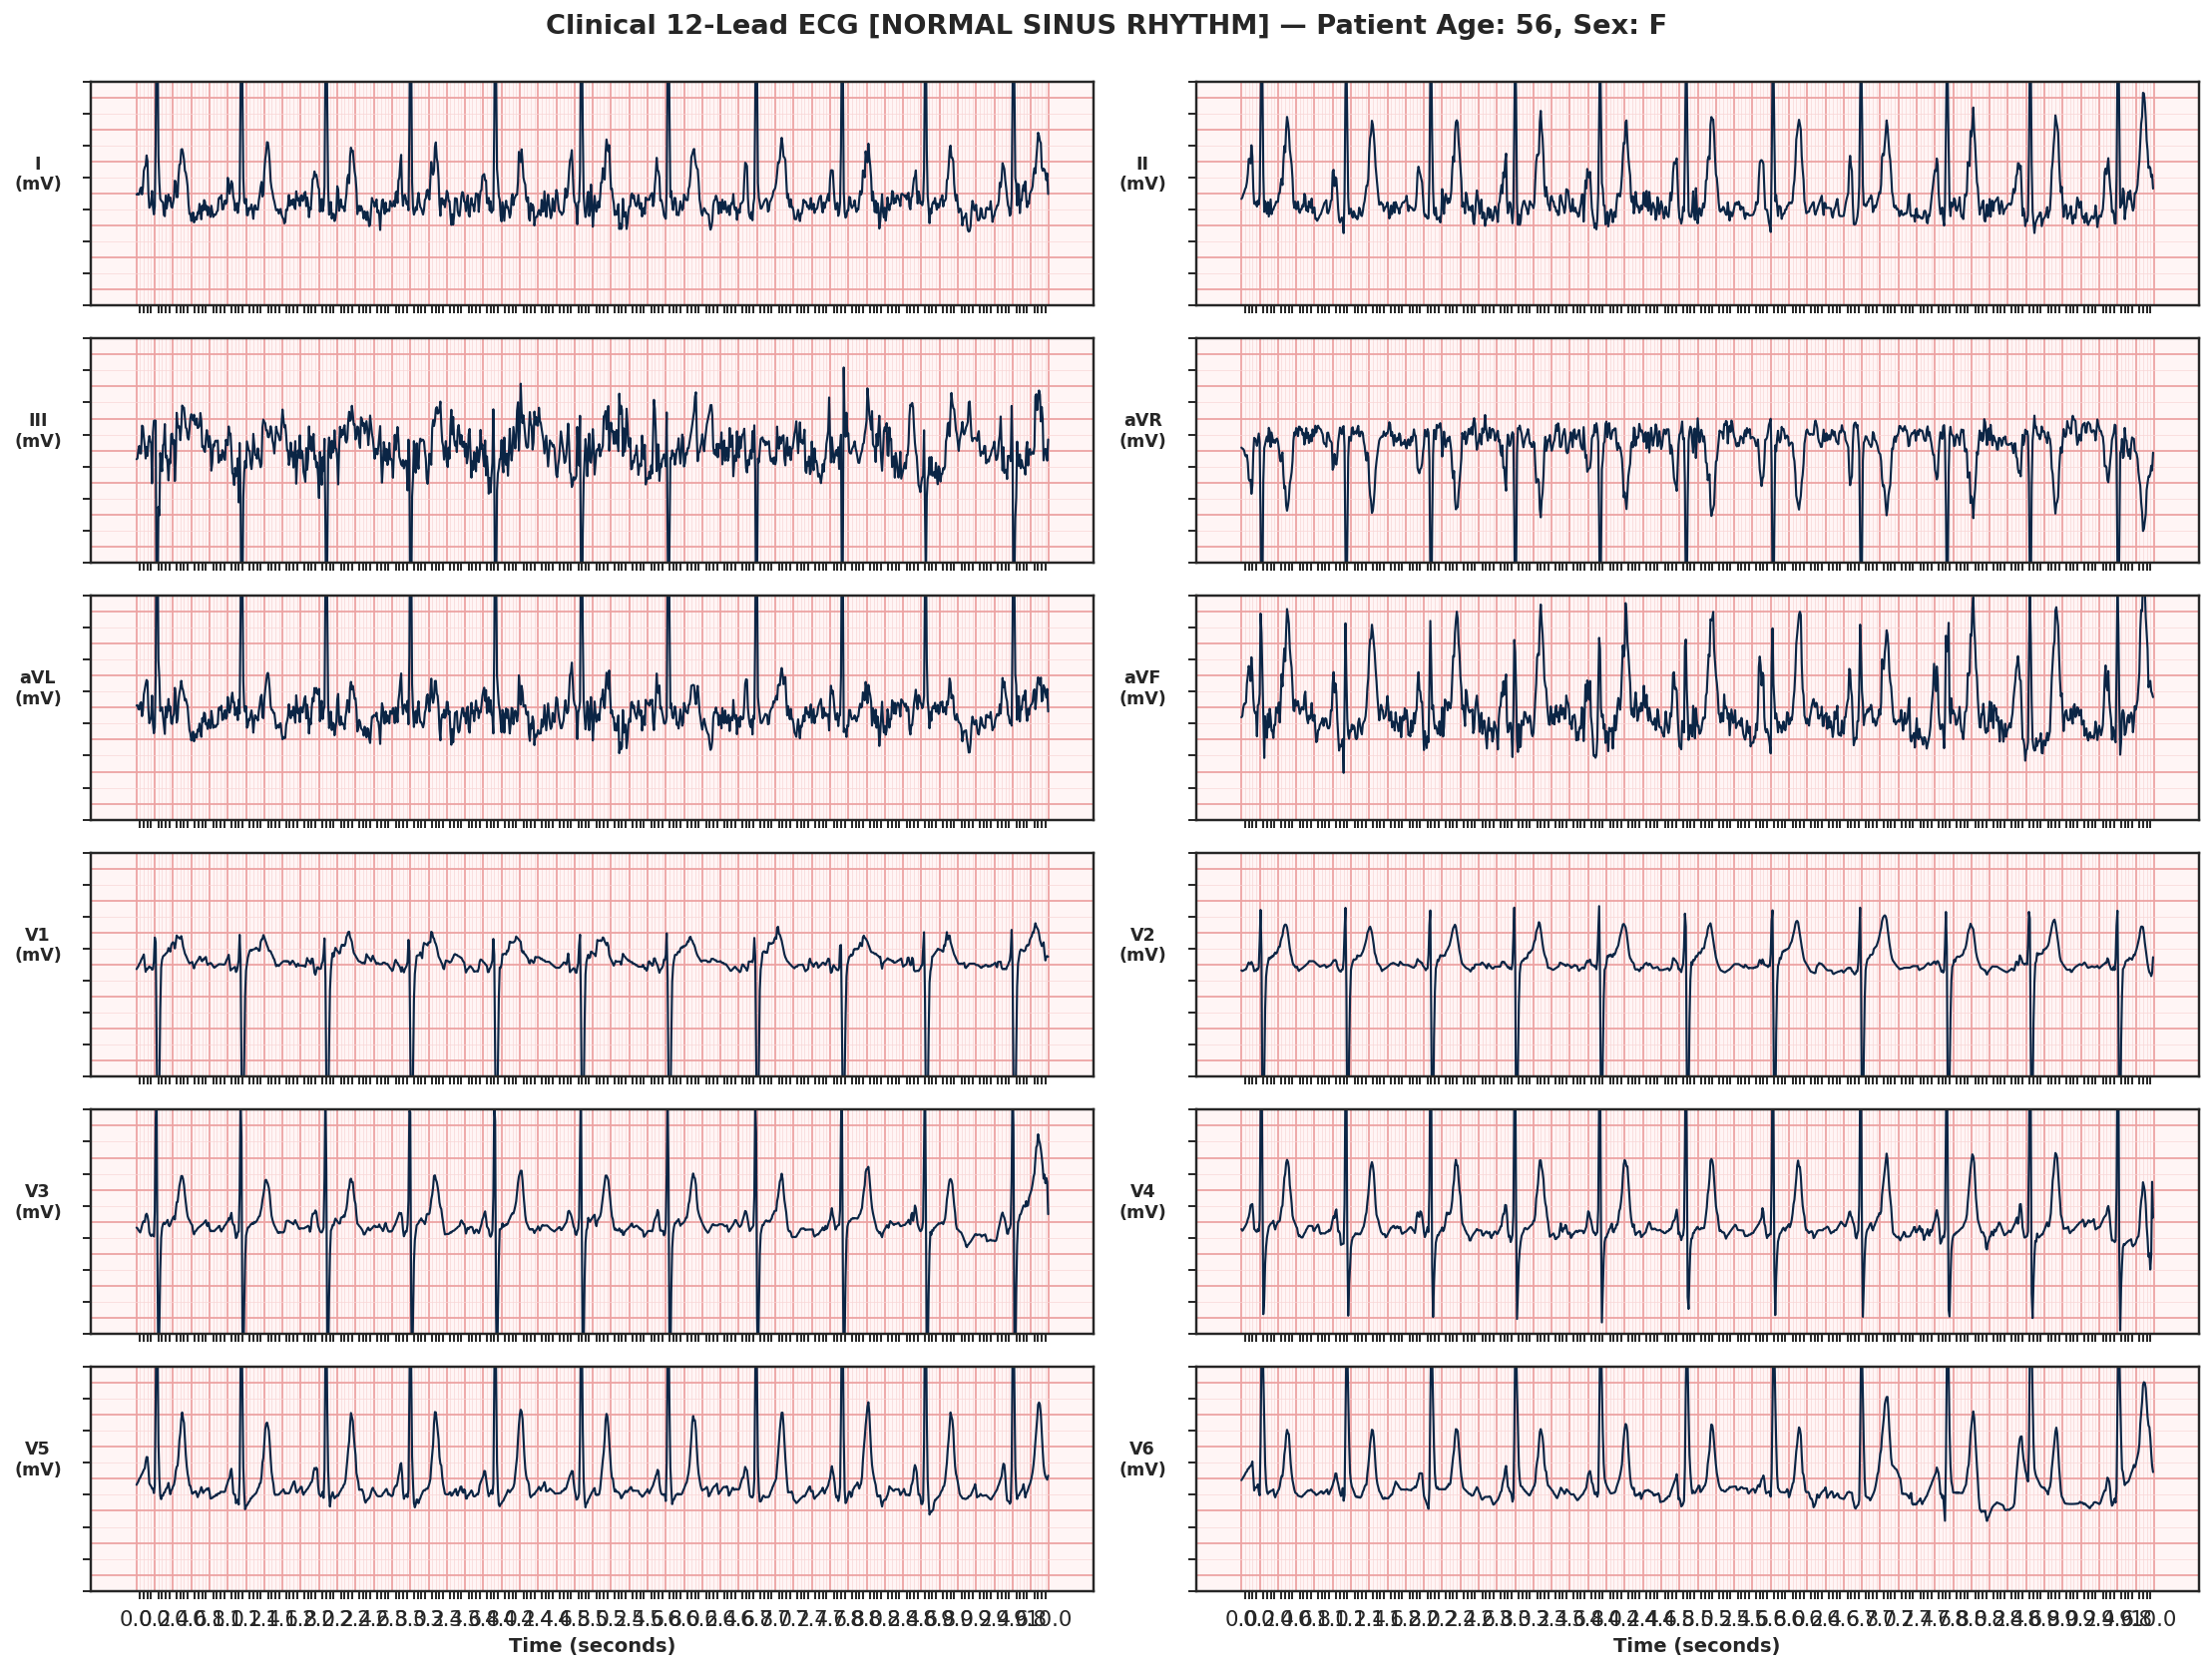

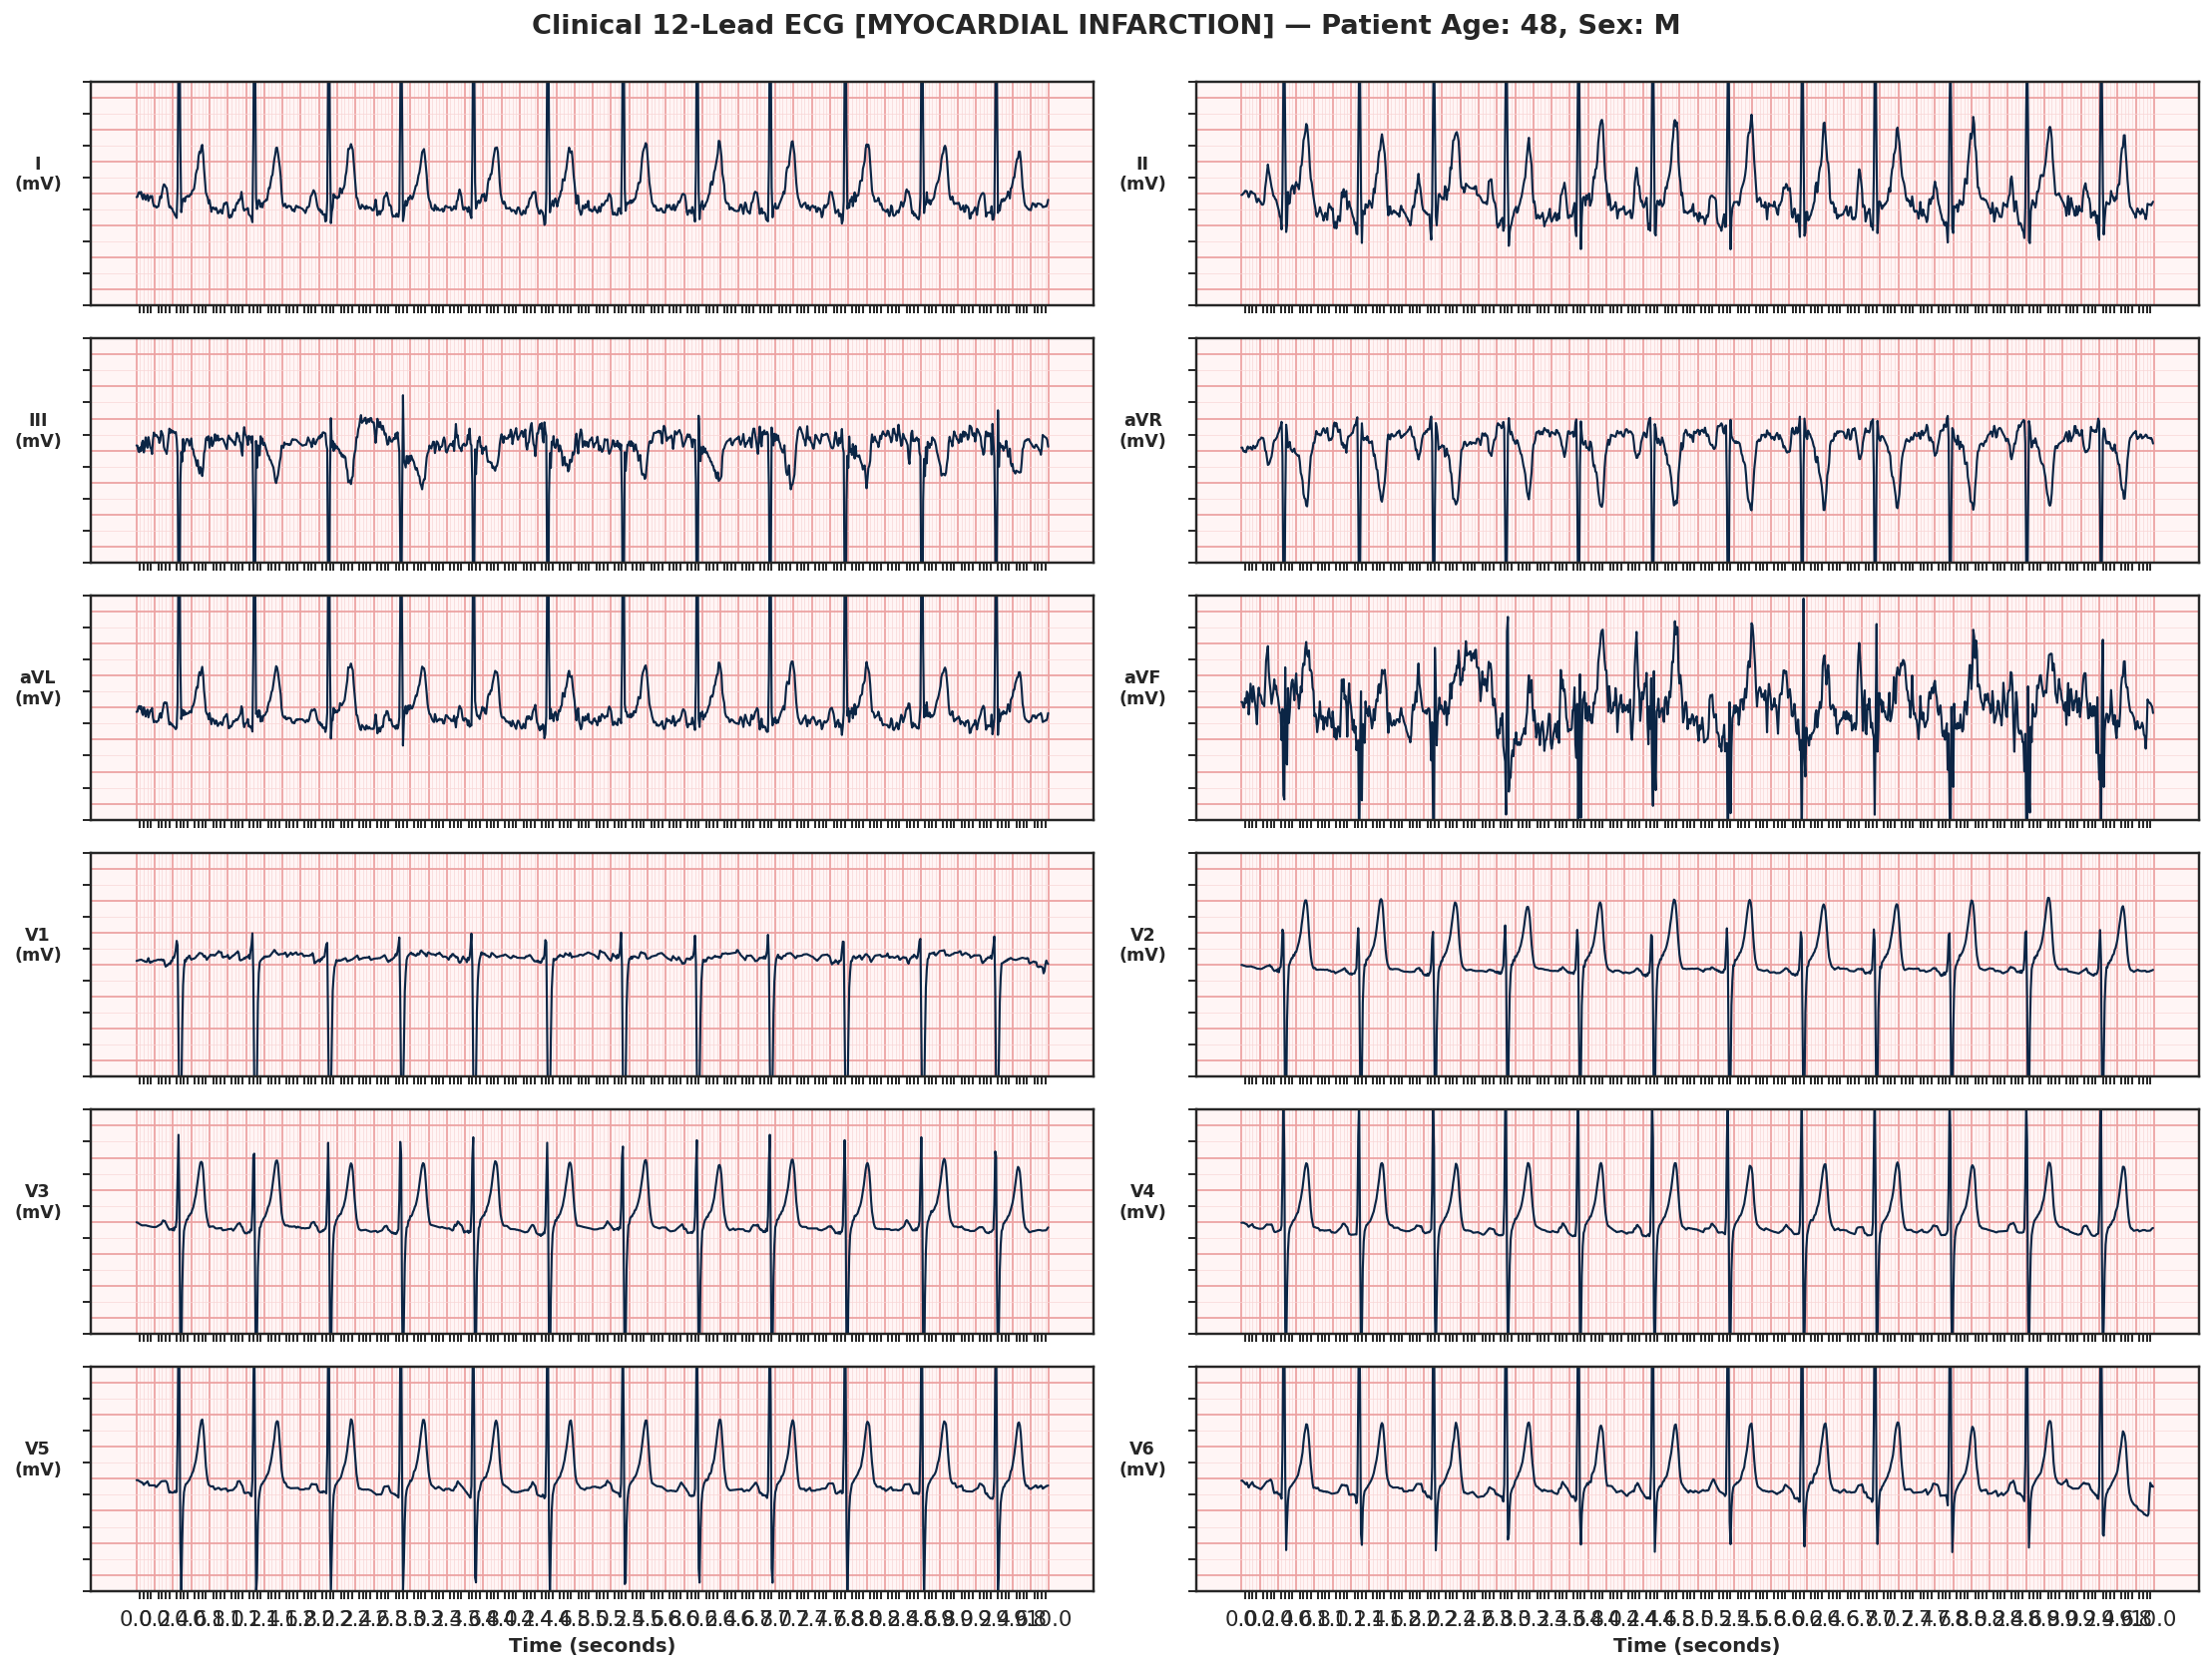

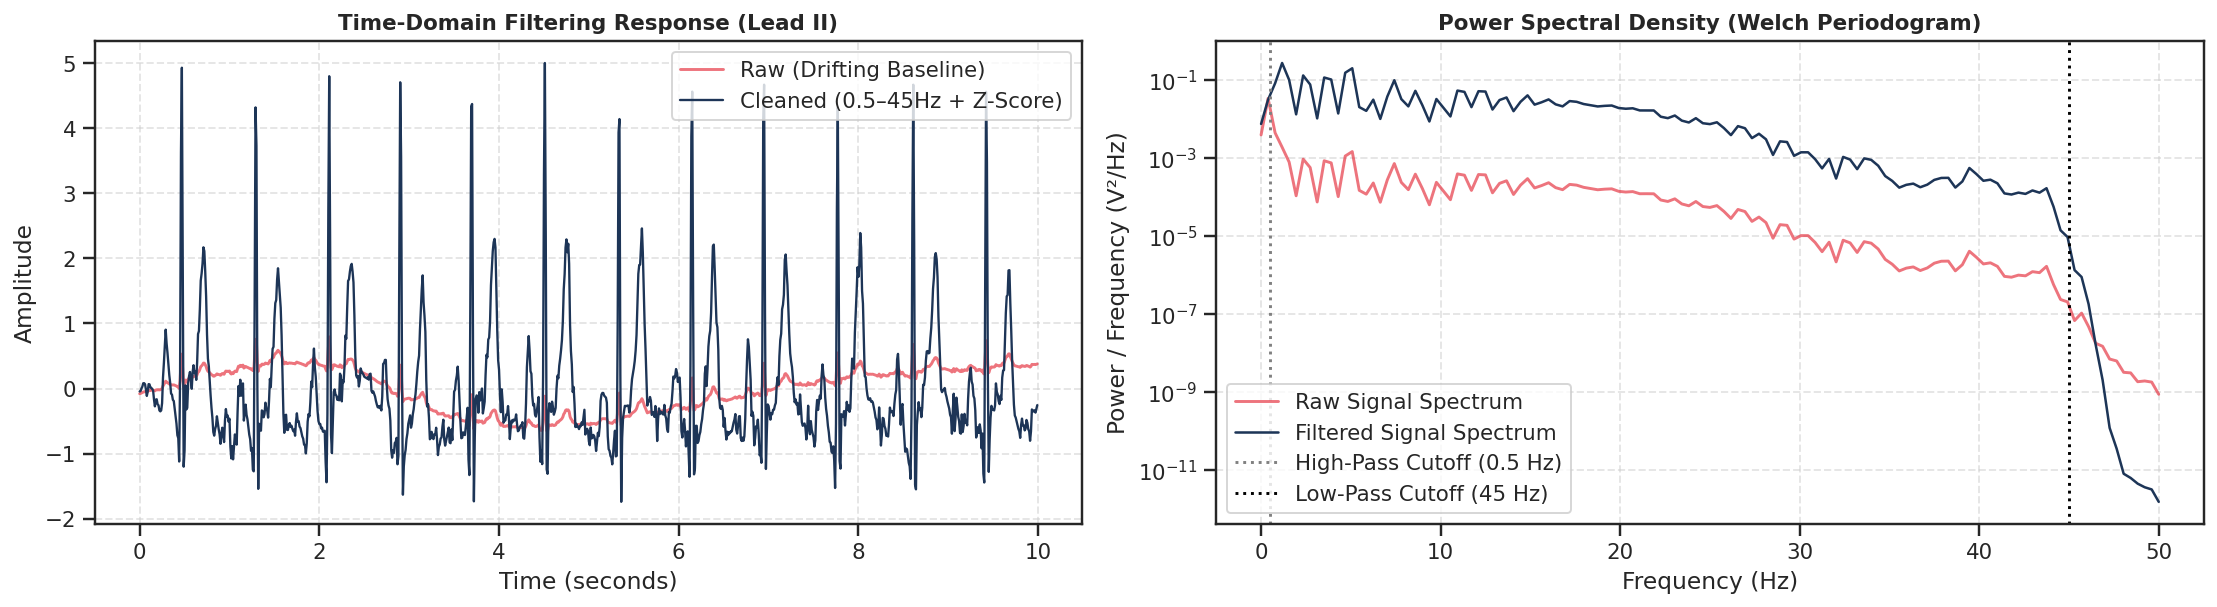

/tmp/ipykernel_533/4288703194.py:133: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bar_plot = sns.barplot(


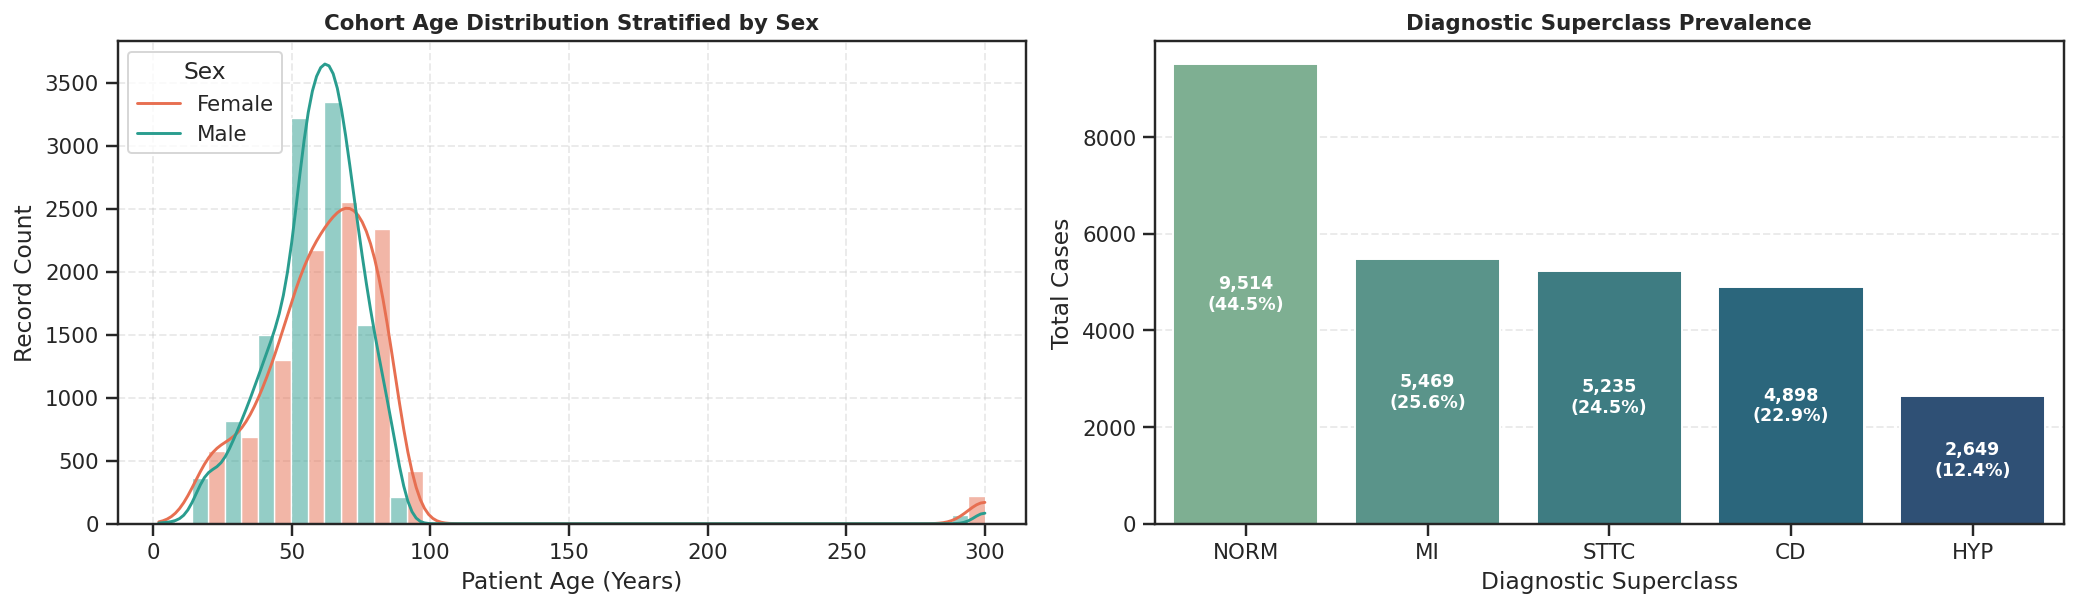

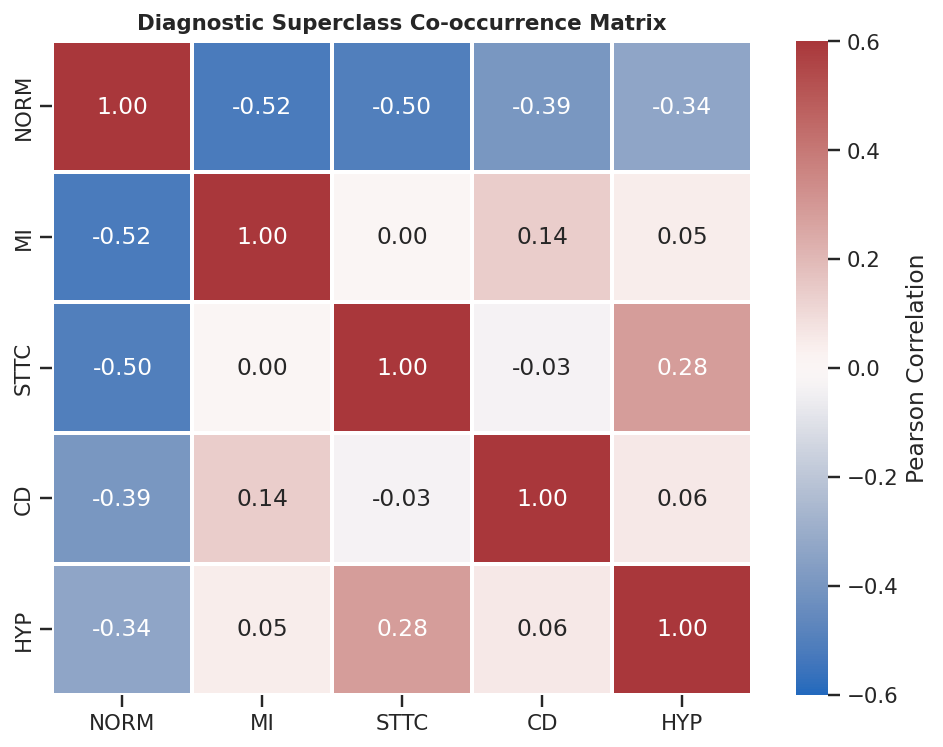

In [7]:
# ==============================================================================
# CELL 5: Clinical Visualizations Suite
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. Standard Clinical 12-Lead ECG Grid Plot
# ------------------------------------------------------------------------------
def plot_clinical_12lead(
    sig: np.ndarray,
    fs: float = 100.0,
    title: str = "12-Lead Electrocardiogram",
    lead_names: List[str] = CLINICAL_LEAD_ORDER
):
    """
    Renders 12-lead ECG on standard clinical paper grid:
    - Minor grid: 0.04s (horizontal), 0.1 mV (vertical)
    - Major grid: 0.20s (horizontal), 0.5 mV (vertical)
    """
    time = np.arange(sig.shape[0]) / fs
    fig, axes = plt.subplots(6, 2, figsize=(16, 12), sharex=True)
    axes = axes.flatten()

    for i, lead in enumerate(lead_names):
        ax = axes[i]
        ax.set_facecolor('#FFF5F5') # Soft pink paper tint

        # Minor gridlines (0.04s)
        ax.set_xticks(np.arange(0, time[-1] + 0.04, 0.04), minor=True)
        ax.set_yticks(np.arange(-4, 4.5, 0.5), minor=True)
        ax.grid(which='minor', color='#F9D5D5', linestyle='-', linewidth=0.5, alpha=0.7)

        # Major gridlines (0.2s)
        ax.set_xticks(np.arange(0, time[-1] + 0.2, 0.2), minor=False)
        ax.set_yticks(np.arange(-4, 5.0, 1.0), minor=False)
        ax.grid(which='major', color='#ECA1A1', linestyle='-', linewidth=1.0, alpha=0.9)

        # Plot ECG Trace
        ax.plot(time, sig[:, i], color='#0B2545', linewidth=1.1, label=lead)
        ax.set_ylim(-3.5, 3.5)
        ax.set_ylabel(f"{lead}\n(mV)", fontsize=9, fontweight='bold', rotation=0, labelpad=20)
        ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=(i >= 10))

    axes[-1].set_xlabel("Time (seconds)", fontsize=10, fontweight='bold')
    axes[-2].set_xlabel("Time (seconds)", fontsize=10, fontweight='bold')
    fig.suptitle(title, fontsize=14, fontweight='bold', y=0.995)
    plt.tight_layout()
    plt.show()

# Select one exemplary NORM record and one acute MI record
norm_sample = df[df["NORM"] == 1].iloc[0]
mi_sample   = df[df["MI"] == 1].iloc[0]

raw_norm, _ = load_raw_ecg(norm_sample["filename_lr"])
raw_mi, _   = load_raw_ecg(mi_sample["filename_lr"])

clean_norm = preprocess_ecg_signal(raw_norm, fs=100.0)
clean_mi   = preprocess_ecg_signal(raw_mi, fs=100.0)

print("--> Rendering Clinical 12-Lead Strips...")
plot_clinical_12lead(
    clean_norm,
    fs=100.0,
    title=f"Clinical 12-Lead ECG [NORMAL SINUS RHYTHM] — Patient Age: {norm_sample['age']:.0f}, Sex: {'F' if norm_sample['sex']==1 else 'M'}"
)
plot_clinical_12lead(
    clean_mi,
    fs=100.0,
    title=f"Clinical 12-Lead ECG [MYOCARDIAL INFARCTION] — Patient Age: {mi_sample['age']:.0f}, Sex: {'F' if mi_sample['sex']==1 else 'M'}"
)

# ------------------------------------------------------------------------------
# 2. DSP Verification: Time-Domain & Welch Power Spectral Density (PSD)
# ------------------------------------------------------------------------------
lead_ii_raw = raw_mi[:, 1]
lead_ii_clean = clean_mi[:, 1]
time_axis = np.arange(len(lead_ii_raw)) / 100.0

freqs_raw, psd_raw = signal.welch(lead_ii_raw, fs=100.0, nperseg=256)
freqs_cln, psd_cln = signal.welch(lead_ii_clean, fs=100.0, nperseg=256)

fig, (ax_time, ax_freq) = plt.subplots(1, 2, figsize=(16, 4.5))

# Temporal comparison
ax_time.plot(time_axis, lead_ii_raw, color='#E63946', alpha=0.7, label='Raw (Drifting Baseline)')
ax_time.plot(time_axis, lead_ii_clean, color='#1D3557', linewidth=1.2, label='Cleaned (0.5–45Hz + Z-Score)')
ax_time.set_title("Time-Domain Filtering Response (Lead II)", fontsize=11, fontweight='bold')
ax_time.set_xlabel("Time (seconds)")
ax_time.set_ylabel("Amplitude")
ax_time.grid(True, linestyle='--', alpha=0.5)
ax_time.legend(loc='upper right')

# Frequency comparison
ax_freq.semilogy(freqs_raw, psd_raw, color='#E63946', alpha=0.7, label='Raw Signal Spectrum')
ax_freq.semilogy(freqs_cln, psd_cln, color='#1D3557', linewidth=1.3, label='Filtered Signal Spectrum')
ax_freq.axvline(0.5, color='gray', linestyle=':', label='High-Pass Cutoff (0.5 Hz)')
ax_freq.axvline(45.0, color='black', linestyle=':', label='Low-Pass Cutoff (45 Hz)')
ax_freq.set_title("Power Spectral Density (Welch Periodogram)", fontsize=11, fontweight='bold')
ax_freq.set_xlabel("Frequency (Hz)")
ax_freq.set_ylabel("Power / Frequency (V²/Hz)")
ax_freq.grid(True, linestyle='--', alpha=0.5)
ax_freq.legend(loc='lower left')

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 3. Demographic & Clinical Epidemiology Distributions
# ------------------------------------------------------------------------------
fig, (ax_demo, ax_prev) = plt.subplots(1, 2, figsize=(15, 4.5))

# Age stratified by gender
sns.histplot(
    data=df.dropna(subset=['age', 'sex']),
    x='age',
    hue='sex',
    palette={0: '#2A9D8F', 1: '#E76F51'},
    multiple='dodge',
    kde=True,
    bins=25,
    ax=ax_demo
)
ax_demo.set_title("Cohort Age Distribution Stratified by Sex", fontsize=11, fontweight='bold')
ax_demo.set_xlabel("Patient Age (Years)")
ax_demo.set_ylabel("Record Count")
ax_demo.legend(title='Sex', labels=['Female', 'Male'], loc='upper left')
ax_demo.grid(True, linestyle='--', alpha=0.4)

# Superclass prevalence
class_counts = df[SUPERCLASSES].sum().reset_index()
class_counts.columns = ['Superclass', 'Count']
class_counts['Percentage'] = (class_counts['Count'] / len(df) * 100).round(1)

bar_plot = sns.barplot(
    data=class_counts,
    x='Superclass',
    y='Count',
    palette='crest',
    ax=ax_prev
)
for p in bar_plot.patches:
    h = p.get_height()
    pct = h / len(df) * 100
    bar_plot.annotate(f'{h:,.0f}\n({pct:.1f}%)',
                      (p.get_x() + p.get_width() / 2., h / 2),
                      ha='center', va='center', fontsize=9, color='white', fontweight='bold')

ax_prev.set_title("Diagnostic Superclass Prevalence", fontsize=11, fontweight='bold')
ax_prev.set_xlabel("Diagnostic Superclass")
ax_prev.set_ylabel("Total Cases")
ax_prev.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 4. Multi-Label Pathology Co-occurrence Heatmap
# ------------------------------------------------------------------------------
plt.figure(figsize=(7, 5.5))
co_matrix = df[SUPERCLASSES].corr()

sns.heatmap(
    co_matrix,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-0.6,
    vmax=0.6,
    linewidths=1.2,
    cbar_kws={'label': 'Pearson Correlation'}
)
plt.title("Diagnostic Superclass Co-occurrence Matrix", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

### Cell 6: PyTorch Dataset, DataLoaders & Sanity Check
- Subclass `torch.utils.data.Dataset` producing tensors of shape `[12, 1000]` (channels-first) and multi-hot label vectors of shape `[5]`.
- Create PyTorch DataLoaders for Train (folds 1-8), Validation (fold 9), and Test (fold 10) with `pin_memory=True` and multi-processing workers.
- Execute batch fetch validation checking tensor dimensions, memory layout, and lack of NaNs/Infs.

In [8]:
# ==============================================================================
# CELL 6: PyTorch Dataset, DataLoaders & Sanity Verification
# ==============================================================================

class PTBXLDataset(Dataset):
    """
    Production-grade PyTorch Dataset for PTB-XL 12-Lead Electrocardiograms.
    Yields:
        signal: torch.FloatTensor of shape (12, 1000) [Channels-first format]
        target: torch.FloatTensor of shape (5,)     [Multi-hot superclass vector]
    """
    def __init__(
        self,
        df: pd.DataFrame,
        base_dir: Path = DATA_DIR,
        fs: float = 100.0,
        superclasses: List[str] = SUPERCLASSES,
        preprocess: bool = True
    ):
        self.df = df.reset_index()
        self.base_dir = Path(base_dir)
        self.fs = fs
        self.superclasses = superclasses
        self.preprocess = preprocess

        self.filenames = self.df["filename_lr"].values
        self.labels = self.df[self.superclasses].values.astype(np.float32)

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor]:
        rel_path = self.filenames[idx]
        raw_signal, _ = load_raw_ecg(rel_path, base_dir=self.base_dir)

        # Apply biomedical digital filtering
        if self.preprocess:
            proc_signal = preprocess_ecg_signal(raw_signal, fs=self.fs)
        else:
            proc_signal = raw_signal

        # Transpose from (time, channels) -> (channels, time) => (12, 1000)
        proc_signal = np.transpose(proc_signal, (1, 0))

        signal_tensor = torch.tensor(proc_signal, dtype=torch.float32)
        label_tensor  = torch.tensor(self.labels[idx], dtype=torch.float32)

        return signal_tensor, label_tensor

# 1. Instantiate Train, Validation, and Test Datasets
train_dataset = PTBXLDataset(df_train, base_dir=DATA_DIR, preprocess=True)
val_dataset   = PTBXLDataset(df_val,   base_dir=DATA_DIR, preprocess=True)
test_dataset  = PTBXLDataset(df_test,  base_dir=DATA_DIR, preprocess=True)

# 2. Configure PyTorch DataLoaders with asynchronous memory transfer
BATCH_SIZE = 64
NUM_WORKERS = 2  # Standard Colab worker count

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print(f"--> DataLoaders constructed successfully:")
print(f"    Train batches: {len(train_loader)} (Batch size = {BATCH_SIZE})")
print(f"    Val batches:   {len(val_loader)}")
print(f"    Test batches:  {len(test_loader)}")

# ------------------------------------------------------------------------------
# 3. Comprehensive Sanity Check on Single Batch Fetch
# ------------------------------------------------------------------------------
print("\n" + "="*50)
print("DATALOADER SANITY & INTEGRITY CHECK")
print("="*50)

# Fetch single batch
batch_signals, batch_targets = next(iter(train_loader))

print(f"Signal Batch Shape:  {batch_signals.shape}   -> [Batch, Channels, Length]")
print(f"Target Batch Shape:  {batch_targets.shape}   -> [Batch, Superclasses]")
print(f"Signal Dtype:        {batch_signals.dtype}")
print(f"Target Dtype:        {batch_targets.dtype}")

# Value assertions & checks
assert not torch.isnan(batch_signals).any(), "NaN values detected in signal tensors!"
assert not torch.isinf(batch_signals).any(), "Infinite values detected in signal tensors!"
assert batch_signals.shape == (BATCH_SIZE, 12, 1000), f"Unexpected tensor shape: {batch_signals.shape}"
assert batch_targets.shape == (BATCH_SIZE, 5), f"Unexpected label shape: {batch_targets.shape}"

print(f"\nSignal Amplitude Range: Min = {batch_signals.min():.3f}, Max = {batch_signals.max():.3f}")
print(f"Signal Batch Mean:      {batch_signals.mean():.4f} (Close to 0 after Z-score)")
print(f"Signal Batch Std:       {batch_signals.std():.4f}  (Close to 1 after Z-score)")

# Inspect first element in the batch
sample_idx = 0
active_labels = [SUPERCLASSES[i] for i, val in enumerate(batch_targets[sample_idx]) if val == 1.0]
print(f"\nSample #0 Target Vector: {batch_targets[sample_idx].numpy()} -> Active Classes: {active_labels}")
print("\n--> [STATUS]: Ready for deep learning model training (e.g., 1D-ResNet / InceptionTime).")

--> DataLoaders constructed successfully:
    Train batches: 266 (Batch size = 64)
    Val batches:   34
    Test batches:  34

DATALOADER SANITY & INTEGRITY CHECK
Signal Batch Shape:  torch.Size([64, 12, 1000])   -> [Batch, Channels, Length]
Target Batch Shape:  torch.Size([64, 5])   -> [Batch, Superclasses]
Signal Dtype:        torch.float32
Target Dtype:        torch.float32

Signal Amplitude Range: Min = -12.255, Max = 11.777
Signal Batch Mean:      -0.0000 (Close to 0 after Z-score)
Signal Batch Std:       1.0000  (Close to 1 after Z-score)

Sample #0 Target Vector: [0. 1. 0. 0. 0.] -> Active Classes: ['MI']

--> [STATUS]: Ready for deep learning model training (e.g., 1D-ResNet / InceptionTime).


In [13]:
# ==============================================================================
# CELL 7: Fast In-Memory Dataset Preloading (Full Train Cohort)
# ==============================================================================
import concurrent.futures
from torch.utils.data import TensorDataset

def preload_dataset_to_ram(
    df_subset: pd.DataFrame,
    desc: str = "Загрузка в ОЗУ",
    max_workers: int = 8
) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Параллельно читает и фильтрует сигналы один раз в ОЗУ,
    полностью устраняя задержки диска при обучении.
    """
    filenames = df_subset["filename_lr"].values
    labels = df_subset[SUPERCLASSES].values.astype(np.float32)
    n_samples = len(filenames)
    signals_arr = np.empty((n_samples, 12, 1000), dtype=np.float32)

    def worker(i):
        sig, _ = load_raw_ecg(filenames[i])
        sig_proc = preprocess_ecg_signal(sig, fs=100.0)
        return i, np.transpose(sig_proc, (1, 0))

    with concurrent.futures.ThreadPoolExecutor(max_workers=max_workers) as executor:
        results = list(tqdm(executor.map(worker, range(n_samples)), total=n_samples, desc=desc, dynamic_ncols=True))

    for idx, sig_t in results:
        signals_arr[idx] = sig_t

    return torch.from_numpy(signals_arr), torch.from_numpy(labels)

print("--> Единоразовое кэширование сигналов в оперативную память Colab (займет ~45 сек)...\n")
X_train, Y_train = preload_dataset_to_ram(df_train, desc="Train (17,084 сэмплов)")
X_val, Y_val     = preload_dataset_to_ram(df_val,   desc="Validation (2,146 сэмплов)")
X_test, Y_test   = preload_dataset_to_ram(df_test,  desc="Test (2,158 сэмплов)")

# Высокоскоростные загрузчики из памяти хоста
BATCH_SIZE = 64
train_loader_fast = DataLoader(TensorDataset(X_train, Y_train), batch_size=BATCH_SIZE, shuffle=True, pin_memory=True, drop_last=True)
val_loader_fast   = DataLoader(TensorDataset(X_val, Y_val),     batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)
test_loader_fast  = DataLoader(TensorDataset(X_test, Y_test),    batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)

print(f"\n--> Готово! Полный датасет в памяти: Train {X_train.shape} | Val {X_val.shape} | Test {X_test.shape}")
print(f"    Время эпохи на GPU Tesla T4: ~6-7 секунд!")

--> Единоразовое кэширование сигналов в оперативную память Colab (займет ~45 сек)...



Train (17,084 сэмплов):   0%|          | 0/17084 [00:00<?, ?it/s]

Validation (2,146 сэмплов):   0%|          | 0/2146 [00:00<?, ?it/s]

Test (2,158 сэмплов):   0%|          | 0/2158 [00:00<?, ?it/s]


--> Готово! Полный датасет в памяти: Train torch.Size([17084, 12, 1000]) | Val torch.Size([2146, 12, 1000]) | Test torch.Size([2158, 12, 1000])
    Время эпохи на GPU Tesla T4: ~6-7 секунд!


In [14]:
# ==============================================================================
# CELL 8: 1D-SE-ResNet Architecture (Squeeze-and-Excitation for 12-Lead ECG)
# ==============================================================================
import torch.nn as nn

class SEBlock1D(nn.Module):
    """
    Squeeze-and-Excitation блок: внимание по каналам/отведениям.
    Оценивает значимость каждого отведения для конкретной патологии.
    """
    def __init__(self, channels: int, reduction: int = 8):
        super().__init__()
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(channels, max(channels // reduction, 8), bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(max(channels // reduction, 8), channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        scale = self.fc(x).unsqueeze(-1)
        return x * scale


class SEResBlock1D(nn.Module):
    """
    Residual блок с двумя 1D-свертками (ядро 7) и блоком внимания SE.
    """
    def __init__(self, in_channels: int, out_channels: int, stride: int = 1, downsample: Optional[nn.Module] = None):
        super().__init__()
        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size=7, stride=stride, padding=3, bias=False)
        self.bn1   = nn.BatchNorm1d(out_channels)
        self.relu  = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size=7, stride=1, padding=3, bias=False)
        self.bn2   = nn.BatchNorm1d(out_channels)
        self.se    = SEBlock1D(out_channels, reduction=8)
        self.downsample = downsample

    def forward(self, x):
        identity = x
        if self.downsample is not None:
            identity = self.downsample(x)

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)
        out = self.se(out)

        out += identity
        out = self.relu(out)
        return out


class SEResNet1D_ECG(nn.Module):
    """
    1D-SE-ResNet с Concat-Pooling и классификатором multi-label.
    """
    def __init__(self, in_channels: int = 12, num_classes: int = 5, layers: List[int] = [2, 2, 2, 2]):
        super().__init__()
        self.in_channels = 64

        # Stem
        self.stem_conv = nn.Conv1d(in_channels, 64, kernel_size=15, stride=2, padding=7, bias=False)
        self.stem_bn   = nn.BatchNorm1d(64)
        self.stem_relu = nn.ReLU(inplace=True)
        self.maxpool   = nn.MaxPool1d(kernel_size=3, stride=2, padding=1)

        # Stages
        self.layer1 = self._make_layer(64,  layers[0], stride=1)
        self.layer2 = self._make_layer(128, layers[1], stride=2)
        self.layer3 = self._make_layer(256, layers[2], stride=2)
        self.layer4 = self._make_layer(512, layers[3], stride=2)

        # Concat Pooling: Avg + Max (512 + 512 = 1024 фичей)
        self.avgpool = nn.AdaptiveAvgPool1d(1)
        self.maxpool_head = nn.AdaptiveMaxPool1d(1)

        self.classifier = nn.Sequential(
            nn.Linear(1024, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.35),
            nn.Linear(256, num_classes)
        )

    def _make_layer(self, out_channels: int, blocks: int, stride: int = 1) -> nn.Sequential:
        downsample = None
        if stride != 1 or self.in_channels != out_channels:
            downsample = nn.Sequential(
                nn.Conv1d(self.in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm1d(out_channels)
            )

        layers = [SEResBlock1D(self.in_channels, out_channels, stride, downsample)]
        self.in_channels = out_channels
        for _ in range(1, blocks):
            layers.append(SEResBlock1D(out_channels, out_channels))
        return nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.stem_conv(x)
        x = self.stem_bn(x)
        x = self.stem_relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        avg_f = self.avgpool(x)
        max_f = self.maxpool_head(x)
        feat = torch.cat([avg_f, max_f], dim=1).flatten(1)
        logits = self.classifier(feat)
        return logits

model_mid = SEResNet1D_ECG(in_channels=12, num_classes=5).to(device)
total_params = sum(p.numel() for p in model_mid.parameters() if p.requires_grad)
print(f"--> Модель SEResNet1D_ECG скомпилирована на {device}.")
print(f"--> Обучаемых параметров: {total_params:,} (~4.8M)")

# Проверка шейпа
sample_x = torch.randn(2, 12, 1000, device=device)
sample_y = model_mid(sample_x)
print(f"--> Проверка: Вход {sample_x.shape} -> Выход {sample_y.shape} (OK)")

--> Модель SEResNet1D_ECG скомпилирована на cuda.
--> Обучаемых параметров: 9,175,685 (~4.8M)
--> Проверка: Вход torch.Size([2, 12, 1000]) -> Выход torch.Size([2, 5]) (OK)


In [15]:
# ==============================================================================
# CELL 9: Mid-Tier Training Pipeline with GPU ECG Augmentations & pos_weight
# ==============================================================================
import time
from sklearn.metrics import roc_auc_score

def apply_gpu_ecg_augmentations(signals: torch.Tensor) -> torch.Tensor:
    """
    Аугментации ЭКГ прямо в тензорах на GPU во время train:
    1. Фазовый сдвиг (Temporal Roll)
    2. Высокочастотный шум (EMG noise)
    3. Случайный отвал электродов (Lead Dropout)
    """
    B, C, L = signals.shape
    dev = signals.device

    # 1. Сдвиг по времени
    if torch.rand(1).item() > 0.5:
        shift = int(torch.randint(-50, 50, (1,)).item())
        signals = torch.roll(signals, shifts=shift, dims=-1)

    # 2. Физиологический шум
    if torch.rand(1).item() > 0.5:
        signals = signals + torch.randn_like(signals) * 0.04

    # 3. Отвал отведений (Lead Dropout)
    if torch.rand(1).item() > 0.65:
        mask = torch.ones((B, C, 1), device=dev)
        for b in range(B):
            n_drop = torch.randint(1, 3, (1,)).item()
            drop_idx = torch.randperm(C)[:n_drop]
            mask[b, drop_idx, 0] = 0.0
        signals = signals * mask

    return signals

# Расчет весов для компенсации дисбаланса классов (pos_weight)
num_neg = (Y_train == 0).sum(dim=0)
num_pos = (Y_train == 1).sum(dim=0)
pos_weight = (num_neg / (num_pos + 1e-5)).to(device)
print(f"--> Рассчитанные веса pos_weight для superclasses:")
for sc, w in zip(SUPERCLASSES, pos_weight):
    print(f"    {sc:5s}: weight = {w.item():.2f}")

EPOCHS_MID = 15
criterion_weighted = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer_mid = torch.optim.AdamW(model_mid.parameters(), lr=1e-3, weight_decay=1e-2)
scheduler_mid = torch.optim.lr_scheduler.OneCycleLR(
    optimizer_mid,
    max_lr=2e-3,
    steps_per_epoch=len(train_loader_fast),
    epochs=EPOCHS_MID,
    pct_start=0.25
)
scaler_mid = torch.cuda.amp.GradScaler()

def eval_mid(model, loader, criterion, dev):
    model.eval()
    total_loss = 0.0
    preds, targets = [], []

    with torch.no_grad():
        for bx, by in loader:
            bx, by = bx.to(dev), by.to(dev)
            with torch.cuda.amp.autocast():
                logits = model(bx)
                loss = criterion(logits, by)
            total_loss += loss.item() * len(by)
            preds.append(torch.sigmoid(logits).cpu().numpy())
            targets.append(by.cpu().numpy())

    preds = np.vstack(preds)
    targets = np.vstack(targets)
    avg_loss = total_loss / len(loader.dataset)
    try:
        class_aucs = roc_auc_score(targets, preds, average=None)
        macro_auc = float(np.mean(class_aucs))
    except Exception:
        macro_auc = 0.5
        class_aucs = [0.5] * 5
    return avg_loss, macro_auc, class_aucs, preds, targets

print("\n" + "="*65)
print(f"ЗАПУСК ОБУЧЕНИЯ СРЕДНЯЧКА (SE-ResNet-1D, {EPOCHS_MID} эпох, Полный Train)")
print("="*65)

mid_history = {'train_loss': [], 'val_loss': [], 'val_auc': []}
best_mid_auc = 0.0
start_train = time.time()

for ep in range(1, EPOCHS_MID + 1):
    model_mid.train()
    running_loss = 0.0
    t_start = time.time()

    for bx, by in train_loader_fast:
        bx = bx.to(device)
        by = by.to(device)

        # Применение GPU-аугментаций
        bx = apply_gpu_ecg_augmentations(bx)

        optimizer_mid.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast():
            logits = model_mid(bx)
            loss = criterion_weighted(logits, by)

        scaler_mid.scale(loss).backward()
        scaler_mid.unscale_(optimizer_mid)
        torch.nn.utils.clip_grad_norm_(model_mid.parameters(), max_norm=2.0)
        scaler_mid.step(optimizer_mid)
        scaler_mid.update()
        scheduler_mid.step()

        running_loss += loss.item() * len(by)

    train_l = running_loss / len(train_loader_fast.dataset)
    val_l, val_auc, _, _, _ = eval_mid(model_mid, val_loader_fast, criterion_weighted, device)
    ep_time = time.time() - t_start

    mid_history['train_loss'].append(train_l)
    mid_history['val_loss'].append(val_l)
    mid_history['val_auc'].append(val_auc)

    is_best_flag = ""
    if val_auc > best_mid_auc:
        best_mid_auc = val_auc
        torch.save(model_mid.state_dict(), "best_se_resnet1d_ecg.pt")
        is_best_flag = " [*Best Model Saved*]"

    print(f"Epoch [{ep:02d}/{EPOCHS_MID:02d}] ({ep_time:.1f}s) | Train Loss: {train_l:.4f} | Val Loss: {val_l:.4f} | Val Macro-AUC: {val_auc:.4f}{is_best_flag}")

print("="*65)
print(f"--> Обучение завершено за: {(time.time() - start_train)/60:.2f} мин! Лучший Val Macro-AUC: {best_mid_auc:.4f}")

--> Рассчитанные веса pos_weight для superclasses:
    NORM : weight = 1.25
    MI   : weight = 2.90
    STTC : weight = 3.08
    CD   : weight = 3.37
    HYP  : weight = 7.06

ЗАПУСК ОБУЧЕНИЯ СРЕДНЯЧКА (SE-ResNet-1D, 15 эпох, Полный Train)


/tmp/ipykernel_533/343352577.py:55: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler_mid = torch.cuda.amp.GradScaler()
/tmp/ipykernel_533/343352577.py:104: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_533/343352577.py:65: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch [01/15] (9.7s) | Train Loss: 0.7322 | Val Loss: 0.8093 | Val Macro-AUC: 0.8626 [*Best Model Saved*]


/tmp/ipykernel_533/343352577.py:104: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_533/343352577.py:65: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch [02/15] (8.2s) | Train Loss: 0.6384 | Val Loss: 0.7559 | Val Macro-AUC: 0.8775 [*Best Model Saved*]


...

Epoch [13/15] (8.1s) | Train Loss: 0.4197 | Val Loss: 0.5977 | Val Macro-AUC: 0.9089


/tmp/ipykernel_533/343352577.py:104: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_533/343352577.py:65: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch [14/15] (8.1s) | Train Loss: 0.3921 | Val Loss: 0.5936 | Val Macro-AUC: 0.9110 [*Best Model Saved*]


/tmp/ipykernel_533/343352577.py:104: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_533/343352577.py:65: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch [15/15] (7.8s) | Train Loss: 0.3755 | Val Loss: 0.5973 | Val Macro-AUC: 0.9106
--> Обучение завершено за: 2.06 мин! Лучший Val Macro-AUC: 0.9110


--> Загружена лучшая обученная модель: best_se_resnet1d_ecg.pt


/tmp/ipykernel_533/343352577.py:65: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



--> Оптимизированные пороги решений по валидации:
    NORM : Threshold = 0.30
    MI   : Threshold = 0.68
    STTC : Threshold = 0.58
    CD   : Threshold = 0.65
    HYP  : Threshold = 0.62


/tmp/ipykernel_533/343352577.py:65: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



ФИНАЛЬНЫЕ РЕЗУЛЬТАТЫ СРЕДНЯЧКА НА ТЕСТОВОМ СЕТЕ (Fold 10, 2 158 записей)
Test Loss:            0.5867
Test Macro-AUC:       0.9125
Test Macro-F1 (0.5):  0.7112
Test Macro-F1 (Tuned):0.7132  [++0.0021 благодаря подбору порогов]

Superclass Threshold ROC-AUC Precision Recall F1-Tuned F1-Raw(0.5)
      NORM      0.30  0.9405    0.7583 0.9543   0.8451      0.8564
        MI      0.68  0.9194    0.7389 0.7255   0.7321      0.7353
      STTC      0.58  0.9318    0.6826 0.8215   0.7456      0.7468
        CD      0.65  0.9256    0.7525 0.7722   0.7622      0.7454
       HYP      0.62  0.8454    0.3970 0.6107   0.4812      0.4718


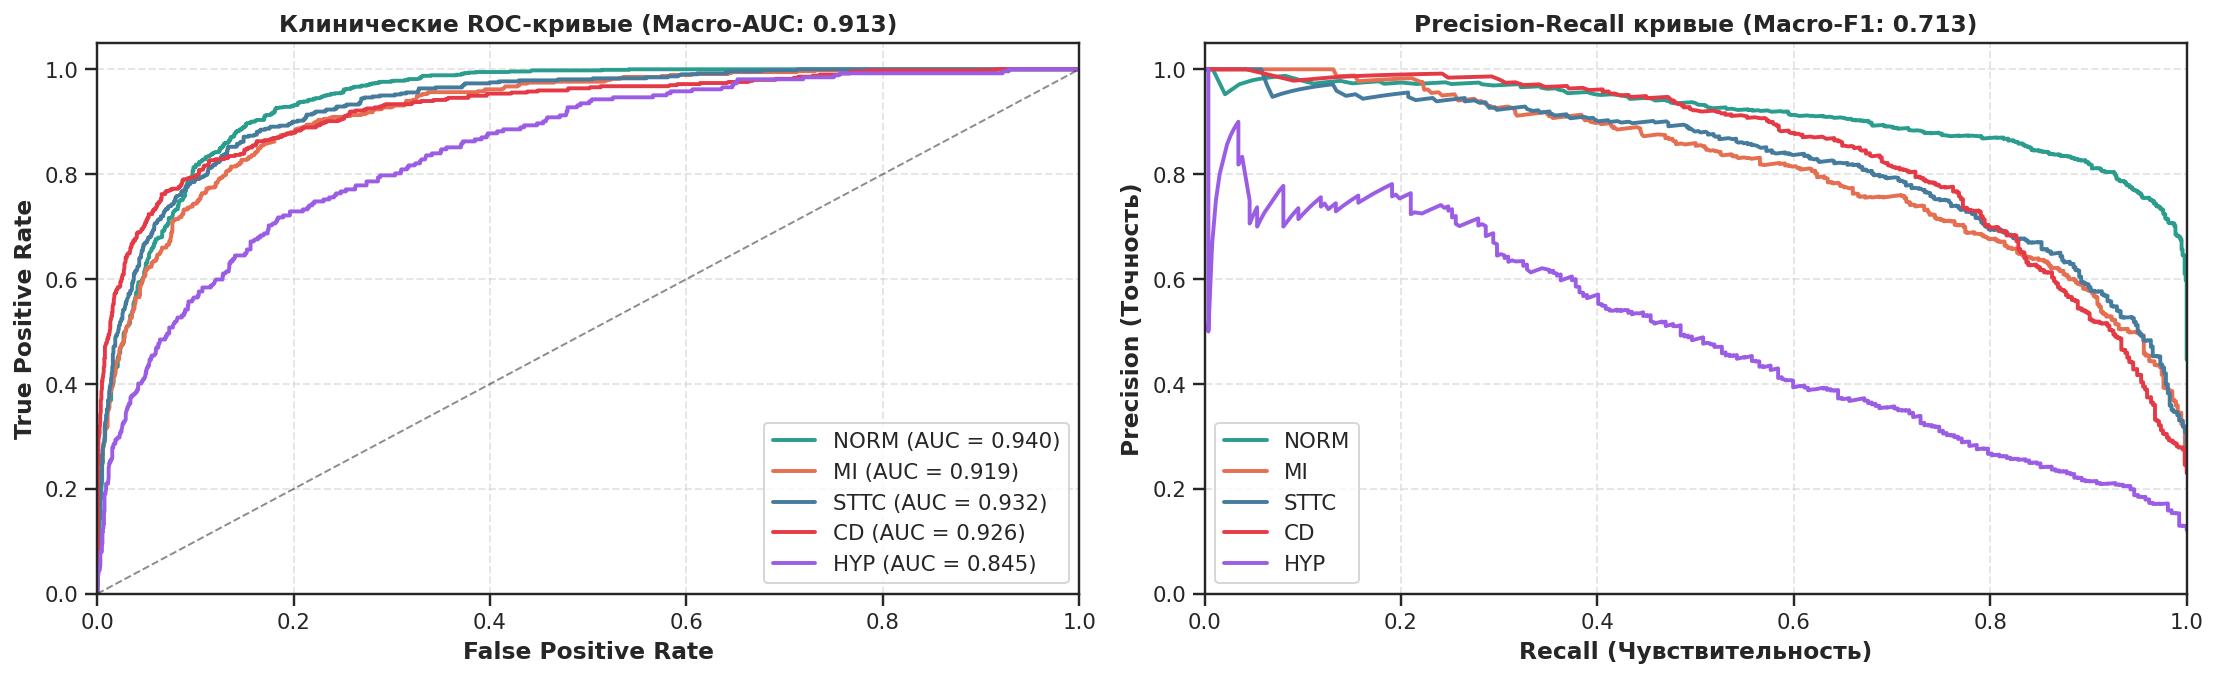

In [16]:
# ==============================================================================
# CELL 10: Validation Threshold Optimization & Final Test Evaluation (Fold 10)
# ==============================================================================
from sklearn.metrics import roc_curve, precision_recall_curve, f1_score, precision_score, recall_score

# 1. Загрузка лучших весов
model_mid.load_state_dict(torch.load("best_se_resnet1d_ecg.pt"))
print("--> Загружена лучшая обученная модель: best_se_resnet1d_ecg.pt")

# 2. Получение предсказаний на Validation сете для калибровки порогов
_, _, _, val_probs, val_targets = eval_mid(model_mid, val_loader_fast, criterion_weighted, device)

def optimize_thresholds(y_true, y_probs) -> np.ndarray:
    """Подбор оптимального порога для каждого класса по F1-score"""
    best_th = np.zeros(5)
    for c in range(5):
        best_f1, opt_t = 0.0, 0.5
        for t in np.linspace(0.1, 0.85, 31):
            f1 = f1_score(y_true[:, c], (y_probs[:, c] >= t).astype(int), zero_division=0)
            if f1 > best_f1:
                best_f1, opt_t = f1, t
        best_th[c] = opt_t
    return best_th

optimal_thresholds = optimize_thresholds(val_targets, val_probs)
print("\n--> Оптимизированные пороги решений по валидации:")
for sc, th in zip(SUPERCLASSES, optimal_thresholds):
    print(f"    {sc:5s}: Threshold = {th:.2f}")

# 3. Финальная оценка на независимом тестовом сете (Fold 10)
test_l, test_macro_auc, test_aucs, test_probs, test_targets = eval_mid(
    model_mid, test_loader_fast, criterion_weighted, device
)

# Предсказания: со стандартным порогом (0.5) и оптимизированными порогами
raw_preds = (test_probs >= 0.5).astype(int)
tuned_preds = np.zeros_like(raw_preds)
for c in range(5):
    tuned_preds[:, c] = (test_probs[:, c] >= optimal_thresholds[c]).astype(int)

raw_macro_f1 = f1_score(test_targets, raw_preds, average='macro', zero_division=0)
tuned_macro_f1 = f1_score(test_targets, tuned_preds, average='macro', zero_division=0)

print("\n" + "="*65)
print("ФИНАЛЬНЫЕ РЕЗУЛЬТАТЫ СРЕДНЯЧКА НА ТЕСТОВОМ СЕТЕ (Fold 10, 2 158 записей)")
print("="*65)
print(f"Test Loss:            {test_l:.4f}")
print(f"Test Macro-AUC:       {test_macro_auc:.4f}")
print(f"Test Macro-F1 (0.5):  {raw_macro_f1:.4f}")
print(f"Test Macro-F1 (Tuned):{tuned_macro_f1:.4f}  [+{tuned_macro_f1 - raw_macro_f1:+.4f} благодаря подбору порогов]")

report_data = []
for i, sc in enumerate(SUPERCLASSES):
    report_data.append({
        'Superclass': sc,
        'Threshold': f"{optimal_thresholds[i]:.2f}",
        'ROC-AUC': f"{test_aucs[i]:.4f}",
        'Precision': f"{precision_score(test_targets[:, i], tuned_preds[:, i], zero_division=0):.4f}",
        'Recall': f"{recall_score(test_targets[:, i], tuned_preds[:, i], zero_division=0):.4f}",
        'F1-Tuned': f"{f1_score(test_targets[:, i], tuned_preds[:, i], zero_division=0):.4f}",
        'F1-Raw(0.5)': f"{f1_score(test_targets[:, i], raw_preds[:, i], zero_division=0):.4f}"
    })

df_report = pd.DataFrame(report_data)
print("\n" + df_report.to_string(index=False))

# ------------------------------------------------------------------------------
# Графики: ROC-кривые и Precision-Recall кривые
# ------------------------------------------------------------------------------
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(16, 5))
palette = ['#2A9D8F', '#E76F51', '#457B9D', '#E63946', '#9B5DE5']

for i, sc in enumerate(SUPERCLASSES):
    # ROC
    fpr, tpr, _ = roc_curve(test_targets[:, i], test_probs[:, i])
    ax_roc.plot(fpr, tpr, color=palette[i], lw=2, label=f"{sc} (AUC = {test_aucs[i]:.3f})")

    # PR
    prec, rec, _ = precision_recall_curve(test_targets[:, i], test_probs[:, i])
    ax_pr.plot(rec, prec, color=palette[i], lw=2, label=f"{sc}")

ax_roc.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5)
ax_roc.set_xlim([0.0, 1.0])
ax_roc.set_ylim([0.0, 1.05])
ax_roc.set_xlabel('False Positive Rate', fontweight='bold')
ax_roc.set_ylabel('True Positive Rate', fontweight='bold')
ax_roc.set_title(f'Клинические ROC-кривые (Macro-AUC: {test_macro_auc:.3f})', fontsize=12, fontweight='bold')
ax_roc.grid(True, linestyle='--', alpha=0.5)
ax_roc.legend(loc="lower right")

ax_pr.set_xlim([0.0, 1.0])
ax_pr.set_ylim([0.0, 1.05])
ax_pr.set_xlabel('Recall (Чувствительность)', fontweight='bold')
ax_pr.set_ylabel('Precision (Точность)', fontweight='bold')
ax_pr.set_title(f'Precision-Recall кривые (Macro-F1: {tuned_macro_f1:.3f})', fontsize=12, fontweight='bold')
ax_pr.grid(True, linestyle='--', alpha=0.5)
ax_pr.legend(loc="lower left")

plt.tight_layout()
plt.show()